In [11]:
import os
import json
import time
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
possible_zips = [
    "/content/drive/MyDrive/KYC DATASET.zip",
    "/content/KYC DATASET.zip"
]

zip_path = next(
    (p for p in possible_zips if os.path.isfile(p)),
    None
)

if zip_path is None:
    raise FileNotFoundError(
        "KYC DATASET.zip was not found. Upload it to Colab or Google Drive."
    )

print("ZIP found:", zip_path)
print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

ZIP found: /content/drive/MyDrive/KYC DATASET.zip
ZIP size (MB): 104.94


In [14]:
extract_path = "/content/kyc_data"
os.makedirs(extract_path, exist_ok=True)

if not os.path.isdir(extract_path) or not any(os.scandir(extract_path)):
    with zipfile.ZipFile(zip_path, "r") as z:
        bad_file = z.testzip()
        if bad_file:
            raise RuntimeError(f"Corrupt ZIP file: {bad_file}")
        z.extractall(extract_path)

dataset_path = None

for root, dirs, files in os.walk(extract_path):
    dirs[:] = [d for d in dirs if not d.startswith("__MACOSX")]

    if "Fake" in dirs and "Original" in dirs:
        dataset_path = root
        break

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find folders named Fake and Original after extraction. "
        "Check the ZIP folder structure."
    )

print("Dataset folder:", dataset_path)
print("Fake folder:", os.path.join(dataset_path, "Fake"))
print("Original folder:", os.path.join(dataset_path, "Original"))

Dataset folder: /content/kyc_data/KYC DATASET
Fake folder: /content/kyc_data/KYC DATASET/Fake
Original folder: /content/kyc_data/KYC DATASET/Original


In [15]:
from pathlib import Path

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

fake_files = [
    str(p) for p in Path(dataset_path, "Fake").rglob("*")
    if p.is_file() and p.suffix.lower() in valid_extensions
]

original_files = [
    str(p) for p in Path(dataset_path, "Original").rglob("*")
    if p.is_file() and p.suffix.lower() in valid_extensions
]

print("Fake images:", len(fake_files))
print("Original images:", len(original_files))
print("Total images:", len(fake_files) + len(original_files))

if len(fake_files) < 3 or len(original_files) < 3:
    raise ValueError("There are too few images in one or both classes.")

Fake images: 100
Original images: 100
Total images: 200


In [16]:
all_paths = np.array(fake_files + original_files)
all_labels = np.array(
    [0] * len(fake_files) + [1] * len(original_files),
    dtype=np.int32
)

# 70% training, 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels
)

# Split remaining 30% equally: 15% validation, 15% test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

class_names = ["Fake", "Original"]

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))

print("\nTraining class counts:", np.bincount(train_labels))
print("Validation class counts:", np.bincount(val_labels))
print("Test class counts:", np.bincount(test_labels))

Training images: 140
Validation images: 30
Test images: 30

Training class counts: [70 70]
Validation class counts: [15 15]
Test class counts: [15 15]


In [17]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

print("Image datasets ready.")

Image datasets ready.


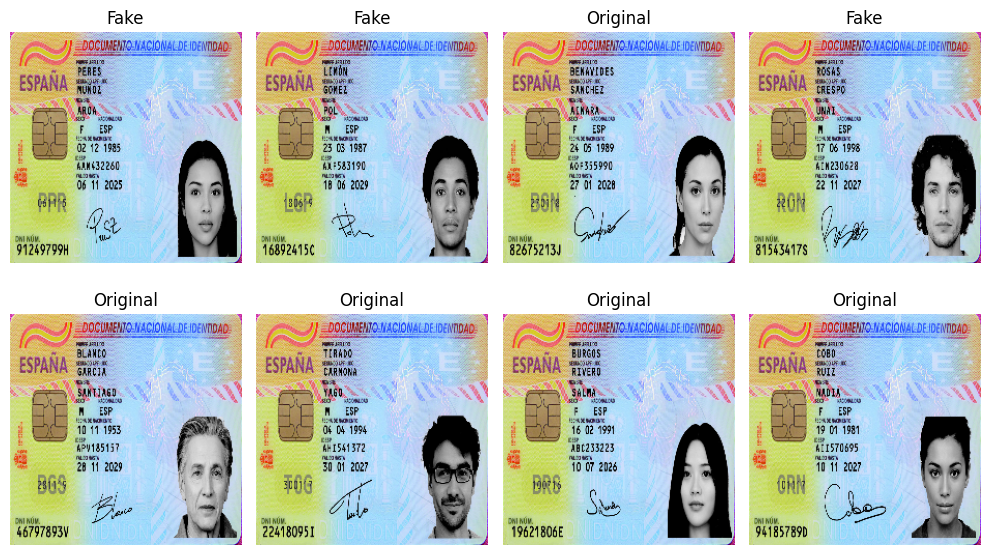

In [18]:
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        label = int(labels[i].numpy())
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.4)(x)
outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,218,788 (16.09 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [20]:
save_dir = "/content/drive/MyDrive/KYC_Phase2"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(
    save_dir, "kyc_efficientnet_best.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

training_time = time.time() - start_time

print(f"Training time: {training_time / 60:.2f} minutes")
print("Best model saved at:", best_model_path)

Epoch 1/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4541 - loss: 0.9611   
Epoch 1: val_loss improved from None to 0.71138, saving model to /content/drive/MyDrive/KYC_Phase2/kyc_efficientnet_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/KYC_Phase2/kyc_efficientnet_best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 66s 4s/step - accuracy: 0.4929 - loss: 0.9477 - val_accuracy: 0.5333 - val_loss: 0.7114
Epoch 2/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.5444 - loss: 0.9478
Epoch 2: val_loss improved from 0.71138 to 0.70622, saving model to /content/drive/MyDrive/KYC_Phase2/kyc_efficientnet_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/KYC_Phase2/kyc_efficientnet_best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 434ms/step - accuracy: 0.5357 - loss: 0.9325 - val_accuracy: 0.5000 - val_loss: 0.7062
Epoch 3/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - accuracy: 0.6403 - loss: 0.6707
Epoch 3: val_loss did not improve from 0.70622
9/9 ━━━━━━━━━━━━━━━━━━

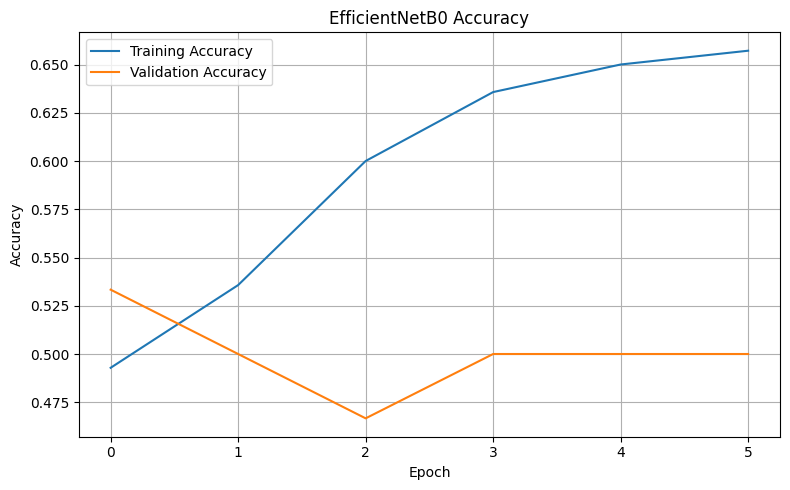

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("EfficientNetB0 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(save_dir, "efficientnet_accuracy.png"),
    dpi=300
)
plt.show()

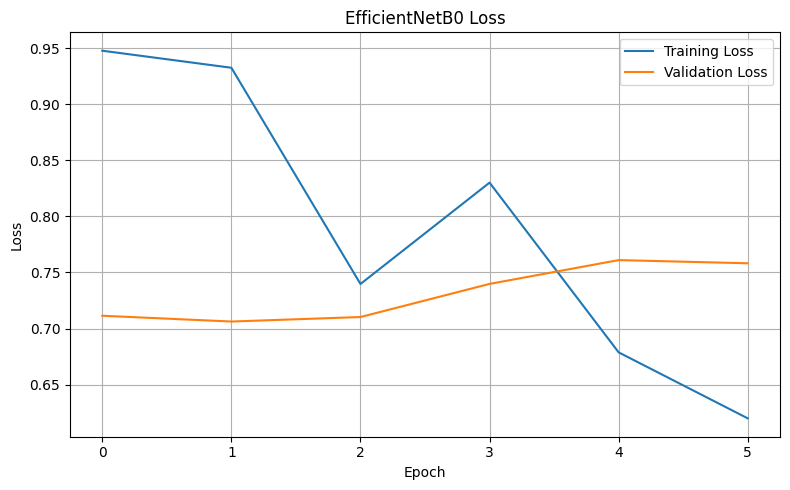

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("EfficientNetB0 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(save_dir, "efficientnet_loss.png"),
    dpi=300
)
plt.show()

In [23]:
y_true = np.concatenate([
    labels.numpy().astype(int)
    for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, pos_label=0, zero_division=0
)
recall = recall_score(
    y_true, y_pred, pos_label=0, zero_division=0
)
f1 = f1_score(
    y_true, y_pred, pos_label=0, zero_division=0
)

print("TEST RESULTS — EfficientNetB0")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision (Fake class): {precision:.4f}")
print(f"Recall (Fake class):    {recall:.4f}")
print(f"F1-score (Fake class):  {f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 14s 7s/step
TEST RESULTS — EfficientNetB0
Accuracy:  0.4667
Precision (Fake class): 0.0000
Recall (Fake class):    0.0000
F1-score (Fake class):  0.0000

Classification report:
              precision    recall  f1-score   support

        Fake       0.00      0.00      0.00        15
    Original       0.48      0.93      0.64        15

    accuracy                           0.47        30
   macro avg       0.24      0.47      0.32        30
weighted avg       0.24      0.47      0.32        30



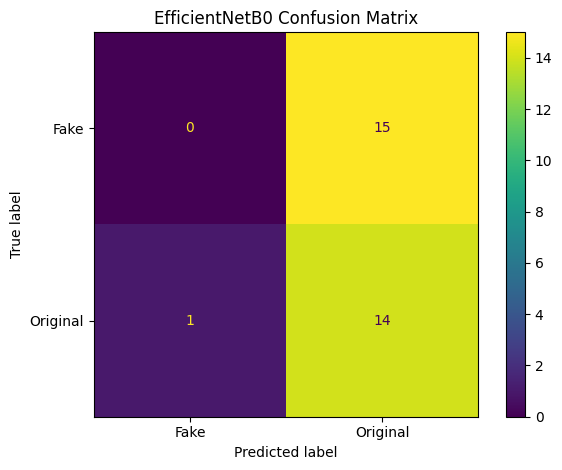

In [24]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(values_format="d")
plt.title("EfficientNetB0 Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(save_dir, "efficientnet_confusion_matrix.png"),
    dpi=300
)
plt.show()

In [25]:
final_model_path = os.path.join(
    save_dir, "kyc_efficientnet_final.keras"
)

model.save(final_model_path)

print("Final model saved:", final_model_path)

Final model saved: /content/drive/MyDrive/KYC_Phase2/kyc_efficientnet_final.keras


In [26]:
results = {
    "model": "EfficientNetB0",
    "epochs_completed": len(history.history["loss"]),
    "training_time_seconds": round(training_time, 2),
    "accuracy": float(accuracy),
    "precision_fake": float(precision),
    "recall_fake": float(recall),
    "f1_score_fake": float(f1),
    "image_size": [224, 224],
    "batch_size": BATCH_SIZE,
    "learning_rate": 0.001,
    "random_seed": SEED,
    "train_images": int(len(train_paths)),
    "validation_images": int(len(val_paths)),
    "test_images": int(len(test_paths)),
    "class_mapping": {"Fake": 0, "Original": 1}
}

results_path = os.path.join(
    save_dir, "efficientnet_results.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nResults saved to:", results_path)

{
    "model": "EfficientNetB0",
    "epochs_completed": 6,
    "training_time_seconds": 83.39,
    "accuracy": 0.4666666666666667,
    "precision_fake": 0.0,
    "recall_fake": 0.0,
    "f1_score_fake": 0.0,
    "image_size": [
        224,
        224
    ],
    "batch_size": 16,
    "learning_rate": 0.001,
    "random_seed": 42,
    "train_images": 140,
    "validation_images": 30,
    "test_images": 30,
    "class_mapping": {
        "Fake": 0,
        "Original": 1
    }
}

Results saved to: /content/drive/MyDrive/KYC_Phase2/efficientnet_results.json


In [27]:
print("Files saved in:", save_dir)

for filename in sorted(os.listdir(save_dir)):
    filepath = os.path.join(save_dir, filename)

    if os.path.isfile(filepath):
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"{filename}: {size_mb:.2f} MB")

Files saved in: /content/drive/MyDrive/KYC_Phase2
efficientnet_accuracy.png: 0.14 MB
efficientnet_confusion_matrix.png: 0.07 MB
efficientnet_loss.png: 0.13 MB
efficientnet_results.json: 0.00 MB
kyc_efficientnet_best.keras: 18.18 MB
kyc_efficientnet_final.keras: 18.18 MB
kyc_vgg19_best.keras: 77.24 MB
kyc_xception_best.keras: 86.15 MB
vgg19_accuracy.png: 0.14 MB
vgg19_confusion_matrix.png: 0.07 MB
vgg19_loss.png: 0.14 MB
vgg19_results.json: 0.00 MB
xception_accuracy.png: 0.14 MB
xception_confusion_matrix.png: 0.08 MB
xception_loss.png: 0.16 MB
xception_results.json: 0.00 MB
